# The air children breathe, five days ahead 🌫️
### Copernicus Atmosphere Monitoring Service (CAMS) · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/air_quality_cams.ipynb)

CAMS, run by ECMWF, forecasts air pollution worldwide twice a day, five days ahead: fine particles (PM2.5), dust, smoke,
ozone and more. This notebook maps the latest PM2.5 forecast over **South Asia**, where winter smog fills the
Indo-Gangetic Plain each November. Change the box for **Mongolia**, where UNICEF works on clean air for children in
Ulaanbaatar, or anywhere else.

*In Google Colab? Press **Runtime → Run all**.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open too, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the dataset page and accept its licence (Download tab, bottom of the page). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    for url, rc in (("https://cds.climate.copernicus.eu/api", "~/.cdsapirc"),
                    ("https://ads.atmosphere.copernicus.eu/api", "~/.adsapirc")):
        with open(os.path.expanduser(rc), "w") as f:
            f.write(f"url: {url}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the place and the time

In [4]:
import datetime as dt
REGION = "South Asia"
AREA   = [38, 60, 5, 100]                  # north, west, south, east; Mongolia: [53, 86, 40, 120]
DATE   = (dt.date.today() - dt.timedelta(days=1)).isoformat()   # yesterday's run is always complete
LEAD   = 48                                # hours ahead
CITIES = [("Lahore", 31.520, 74.359), ("Delhi", 28.614, 77.209), ("Patna", 25.594, 85.137), ("Dhaka", 23.811, 90.413)]

## 2 · Get the CAMS forecast from the Atmosphere Data Store

In [5]:
cams = ekd.from_source("ads", "cams-global-atmospheric-composition-forecasts", {
    "variable": "particulate_matter_2.5um", "date": f"{DATE}/{DATE}", "time": "00:00", "type": "forecast",
    "leadtime_hour": str(LEAD), "area": AREA, "data_format": "grib"}).to_fieldlist()
pm = cams.to_xarray()
pm25 = pm[list(pm.data_vars)[0]].squeeze() * 1e9               # kg/m3 -> µg/m3
valid = dt.datetime.fromisoformat(DATE) + dt.timedelta(hours=LEAD)
print(f"Highest PM2.5: {float(pm25.max()):.0f} µg/m³ (WHO 24-hour guideline: 15 µg/m³)")

Highest PM2.5: 215 µg/m³ (WHO 24-hour guideline: 15 µg/m³)


## 3 · Map it

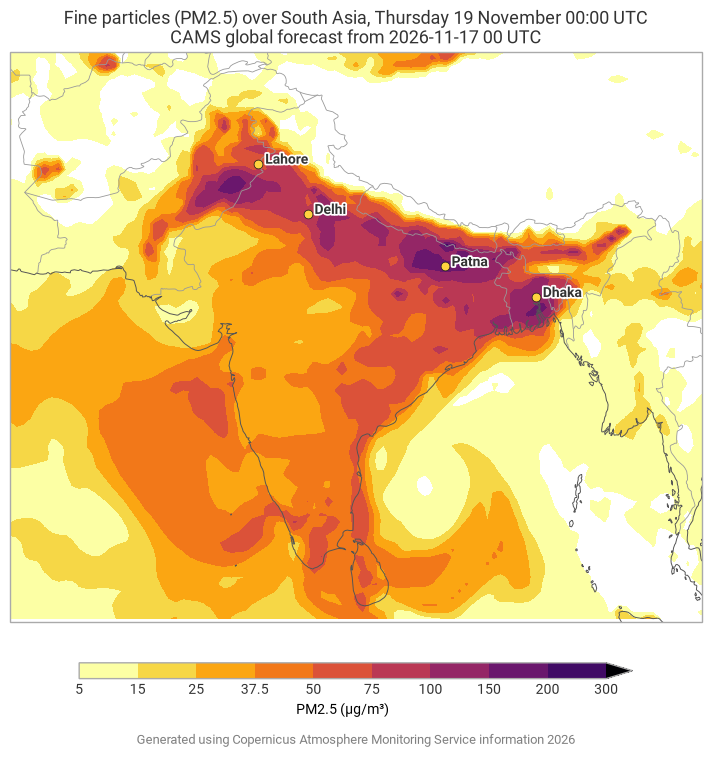

In [6]:
style = ekp.styles.Style(levels=[5, 15, 25, 37.5, 50, 75, 100, 150, 200, 300], colors="inferno_r", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]])
chart.contourf(pm25, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.6)
for name, la, lo in CITIES:
    chart.scatter(x=[lo], y=[la], s=40, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
    chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label="PM2.5 (µg/m³)")
chart.title(f"Fine particles (PM2.5) over {REGION}, {valid:%A %d %B %H:00} UTC\nCAMS global forecast from {DATE} 00 UTC",
            fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("air_quality_cams.png")
chart.show()

## 4 · Your turn 🌍

- **Mongolia:** `REGION = "Mongolia"`, `AREA = [53, 86, 40, 120]`, cities `[("Ulaanbaatar", 47.886, 106.906)]`.
- **Desert dust over the Sahel:** variable `"dust_aerosol_optical_depth_550nm"`, `AREA = [25, -20, 5, 40]`.
- **Another day ahead:** `LEAD` up to 120 hours.
- CAMS global runs at about 40 km, so it smooths out pollution trapped in narrow valleys such as Ulaanbaatar's.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0 for these datasets). Credit:
*Generated using Copernicus Climate Change Service / Atmosphere Monitoring Service information [year].*
ECMWF runs both services for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)